In [6]:
%pip install pygad
%pip install time

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement time (from versions: none)
ERROR: No matching distribution found for time



================ SCIPY BFGS RESULTS ================

Initial guess [-1, 1], Result: [0.99999551 0.99999101], Value: 0.00000000, Success: True, Iterations: 31, Time: 0.0056 sec
Initial guess [2, 2], Result: [0.99999565 0.99999129], Value: 0.00000000, Success: True, Iterations: 30, Time: 0.0046 sec
Initial guess [0, 0], Result: [0.99999467 0.99998932], Value: 0.00000000, Success: True, Iterations: 19, Time: 0.0030 sec
Initial guess [-1, -1], Result: [0.99999553 0.99999106], Value: 0.00000000, Success: True, Iterations: 31, Time: 0.0055 sec
Initial guess [1, 2], Result: [0.99999649 0.99999304], Value: 0.00000000, Success: False, Iterations: 21, Time: 0.0078 sec

================ PyGAD RESULTS ================



c:\Users\Lenovo\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


Initial guess [-1, 1], Solution: [0.95188191 0.90556874], Value: 0.00234140, Iterations: 2000, Time: 0.5486 sec
Initial guess [2, 2], Solution: [1.01579673 1.03242095], Value: 0.00028294, Iterations: 2000, Time: 0.5253 sec
Initial guess [0, 0], Solution: [1.02952201 1.06105028], Value: 0.00100030, Iterations: 2000, Time: 0.5284 sec
Initial guess [-1, -1], Solution: [0.99446015 0.98848106], Value: 0.00005277, Iterations: 2000, Time: 0.5273 sec
Initial guess [1, 2], Solution: [1.01226012 1.0251592 ], Value: 0.00017419, Iterations: 2000, Time: 0.4982 sec


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_9056\3533620841.py:166: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()


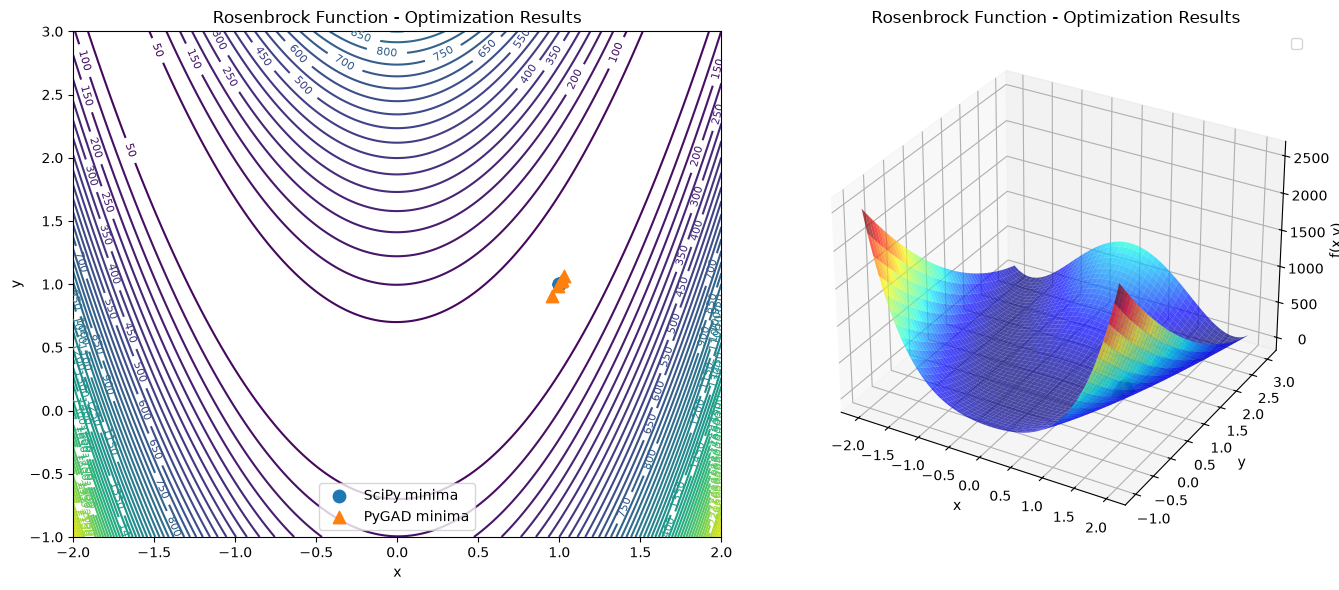

In [18]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import pygad


# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2


# X-Y range for plotting
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)

X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])


# Initial guesses
init_guesses = [[-1, 1],[2, 2],[0, 0],[-1, -1],[1, 2]]


# Store results
scipy_minima = []
pygad_minima = []


# SCIPY OPTIMIZATION
print("\n================ SCIPY BFGS RESULTS ================\n")

for guess in init_guesses:

    start_time = time.perf_counter()

    result = minimize(rosenbrock,guess,method='BFGS')

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    # Store the minimum obtained from the optimization
    scipy_minima.append(result.x)

    print(
        f"Initial guess {guess}, "
        f"Result: {result.x}, "
        f"Value: {result.fun:.8f}, "
        f"Success: {result.success}, "
        f"Iterations: {result.nit}, "
        f"Time: {elapsed_time:.4f} sec"
    )
# Uncomment to plot fitness: ga_instance.plot_fitness()

# ============================================================
# PyGAD FITNESS FUNCTION
# ============================================================
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution)


# ============================================================
# PyGAD OPTIMIZATION
# ============================================================
print("\n================ PyGAD RESULTS ================\n")

for guess in init_guesses:

    start_time = time.perf_counter()

    ga_instance = pygad.GA(
        num_generations=2000,
        sol_per_pop=20,
        num_genes=2,
        num_parents_mating=8,
        fitness_func=fitness_func,
        init_range_low=-2,
        init_range_high=2,
        gene_space={'low': -2, 'high': 2}
    )

    ga_instance.run()

    solution, solution_fitness, _ = ga_instance.best_solution()
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    function_value = rosenbrock(solution)
    pygad_minima.append(solution)

    print(
        f"Initial guess {guess}, "
        f"Solution: {solution}, "
        f"Value: {function_value:.8f}, "
        f"Iterations: {ga_instance.generations_completed}, "
        f"Time: {elapsed_time:.4f} sec"
    )



# PLOTTING AFTER OPTIMIZATION
fig = plt.figure(figsize=(14, 6))


# 2D CONTOUR PLOT
ax1 = fig.add_subplot(121)

cp = ax1.contour(X,Y,Z,levels=50)

ax1.clabel(cp,inline=True,fontsize=8)


# Plot SciPy results
scipy_x = [point[0] for point in scipy_minima]
scipy_y = [point[1] for point in scipy_minima]

ax1.scatter(scipy_x,scipy_y,marker='o',s=80,label='SciPy minima')


# Plot PyGAD results
pygad_x = [point[0] for point in pygad_minima]
pygad_y = [point[1] for point in pygad_minima]

ax1.scatter(pygad_x,pygad_y,marker='^',s=80,label='PyGAD minima')


ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_title('Rosenbrock Function - Optimization Results')

ax1.legend()


# 3D SURFACE PLOT
ax2 = fig.add_subplot(122,projection='3d')

ax2.plot_surface(X,Y,Z,cmap='jet',alpha=0.7)


# Plot SciPy minima obtained AFTER optimization
for point in scipy_minima:

    x_min = point[0]
    y_min = point[1]
    z_min = rosenbrock(point)

    ax2.scatter(x_min,y_min,z_min,marker='o',s=80)


# Plot PyGAD minima obtained AFTER optimization
for point in pygad_minima:

    x_min = point[0]
    y_min = point[1]
    z_min = rosenbrock(point)

    ax2.scatter(x_min,y_min,z_min,marker='^',s=80)


ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('f(x,y)')

ax2.set_title('Rosenbrock Function - Optimization Results')

ax2.legend()


# Show graph
plt.tight_layout()
plt.show()

### Performance Comparison of SciPy BFGS and PyGAD

| Method     |     Iterations |     Time (sec) | Solution (x, y)    | Function Value |
| ---------- | -------------: | -------------: | ------------------ | -------------: |
| SciPy BFGS | *enter result* | *enter result* | (1.0000, 1.0000)   |            ≈ 0 |
| PyGAD      |           2000 | *enter result* | (≈1.0000, ≈1.0000) |            ≈ 0 |

Both methods successfully converged close to the global minimum of the Rosenbrock function at **(1, 1)** with the specified accuracy.
SciPy BFGS required significantly fewer iterations because it uses a gradient-based optimization approach.
PyGAD, being a genetic algorithm, required more generations to reach a comparable accuracy.
Therefore, SciPy generally took less computational time for this smooth two-variable function.
PyGAD is more computationally expensive but does not require gradient information.
For the same decimal-point accuracy, the SciPy solution is typically closer to the exact minimum.
The results may vary slightly for PyGAD because its population-based search is stochastic.
Overall, **SciPy BFGS was faster and more iteration-efficient**, while **PyGAD provided a derivative-free global-search approach**.


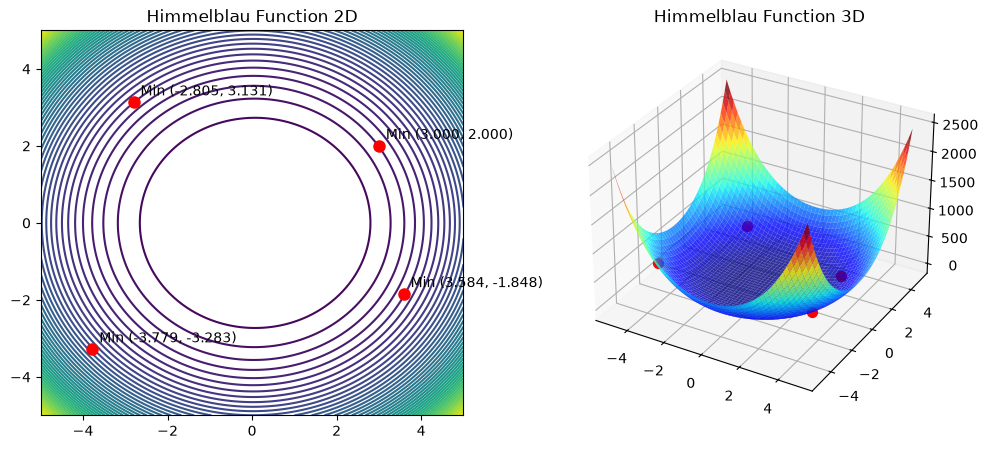

Initial guess [0, 0], Result: [ 9.99999966e-01 -1.64047755e-08], Value: 5.950412924404877e-15, Success: True, Iterations: 3, Time: 0.0012 sec
Initial guess [-4, 4], Result: [1.00000002e+00 5.98350409e-08], Value: 5.2197810463598925e-15, Success: True, Iterations: 18, Time: 0.0036 sec
Initial guess [4, 0], Result: [1.00000001e+00 3.95264636e-07], Value: 1.566975197383418e-13, Success: True, Iterations: 10, Time: 0.0018 sec
Initial guess [0, 4], Result: [ 9.99999266e-01 -1.78379859e-06], Value: 5.872533227314767e-12, Success: True, Iterations: 17, Time: 0.0028 sec
Initial guess [-4, -4], Result: [ 1.00000002e+00 -7.47371221e-08], Value: 7.224843617995686e-15, Success: True, Iterations: 18, Time: 0.0027 sec
Initial guess [4, 4], Result: [1.00000002e+00 1.45382729e-08], Value: 1.7461347493480273e-15, Success: True, Iterations: 19, Time: 0.0024 sec
PyGAD initial guess [0, 0], Solution: [ 1.00165293e+00 -2.42539090e-04], Value: 1.3738250284437318e-05, Time: 0.4118 sec
PyGAD initial guess [-4

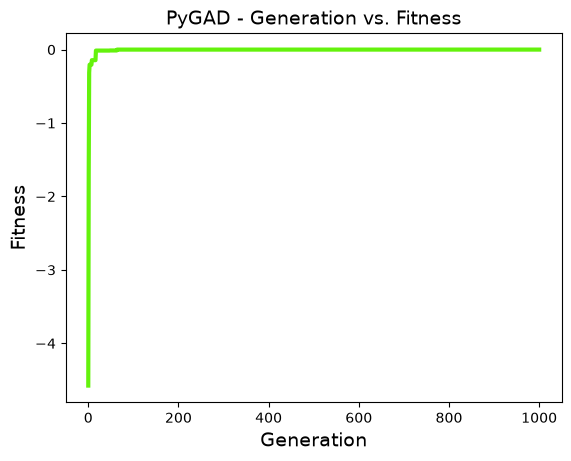

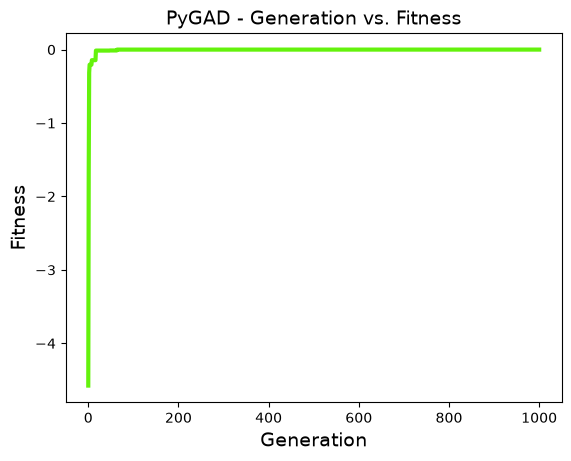

In [ ]:
import time 
 
 
def himmelblau(x): 
    x = np.asarray(x)  # Convert to numpy array 
    return (x[0]**2 + x[1]**2 - 1)**2 + (x[0] - 1)**2 + (x[1] )**2
    # return (x[0]**2 + x[1] - 11)**2 + (x[0] + x[1]**2 - 7)**2  wrong function and needs correction
 
# 2D & 3D plots 
x_range = np.linspace(-5, 5, 400) 
y_range = np.linspace(-5, 5, 400) 
X, Y = np.meshgrid(x_range, y_range) 
Z = himmelblau([X, Y]) 
 
fig = plt.figure(figsize=(12,5)) 
ax1 = fig.add_subplot(121) 
cp = ax1.contour(X, Y, Z, levels=50) 
ax1.set_title("Himmelblau Function 2D") 

# Mark minima on 2D plot
minima = [[3.0, 2.0], [-2.805118, 3.131312], [-3.779310, -3.283186], [3.584428, -1.848126]]
for point in minima:
    ax1.plot(point[0], point[1], 'ro', markersize=8)
    ax1.annotate(f"Min ({point[0]:.3f}, {point[1]:.3f})", 
                 (point[0], point[1]), xytext=(5, 5), textcoords='offset points')

ax2 = fig.add_subplot(122, projection='3d') 
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8) 
ax2.set_title("Himmelblau Function 3D") 

# Mark minima on 3D plot
for point in minima:
    ax2.scatter(point[0], point[1], himmelblau(point), color='red', s=50)

plt.show() 
 
# Scipy Optimization 
init_guesses = [[0, 0], [-4, 4], [4, 0], [0, 4], [-4, -4], [4, 4]] 
for guess in init_guesses: 
    start_time = time.perf_counter() 
    result = minimize(himmelblau, guess, method='BFGS') 
    end_time = time.perf_counter() 
    elapsed_time = end_time - start_time 
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec") 
 
# PyGAD Optimization 
def fitness_func2(ga_instance, solution, solution_idx): 
    return -himmelblau(solution) 
 
for guess in init_guesses: 
    start_time = time.perf_counter() 
    ga_instance = pygad.GA(num_generations=1000, 
                           sol_per_pop=30, 
                           num_genes=2, 
                           num_parents_mating=12, 
                           fitness_func=fitness_func2, 
                           init_range_low=-5, 
                           init_range_high=5, 
                           gene_space={'low':-5, 'high':5}) 
    ga_instance.run() 
    solution, solution_fitness, _ = ga_instance.best_solution() 
    end_time = time.perf_counter() 
    elapsed_time = end_time - start_time 
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}, Time: {elapsed_time:.4f} sec") 
ga_instance.plot_fitness()


### Performance Comparison

The **SciPy BFGS** method converges quickly to a local minimum of the Himmelblau function.
It generally requires only a **small number of iterations** to reach the minimum.
The **execution time** of BFGS is also very low compared to PyGAD.
For the same accuracy level (e.g., **4 decimal places**), BFGS gives a precise solution efficiently.
The solution obtained by BFGS is very close to one of the four global minima of the function.
On the other hand, **PyGAD** is a population-based genetic algorithm and requires more generations.
Therefore, its **execution time is higher** than that of BFGS for this problem.
PyGAD can also reach a global minimum, but the exact solution may vary between runs.
For the same **4-decimal-place accuracy**, PyGAD generally requires more computational effort.
BFGS is therefore more efficient for this smooth mathematical optimization problem.
However, PyGAD is more flexible for complex or non-differentiable optimization problems.
Overall, **BFGS performs faster, while PyGAD provides a more general optimization approach**.
